# CodeAlpha ML Internship — Task 3: Handwritten Character Recognition

**Objective:** identify handwritten characters from images using deep learning.

**Approach:** a Convolutional Neural Network (CNN) built with TensorFlow/Keras, compared against a classical baseline (SVM on raw pixels), with data augmentation, learning-rate scheduling, early stopping and a detailed error analysis. A final cell lets you recognise your **own** handwritten image.

**Dataset:** 10,000 real MNIST handwritten digit images (28×28 grayscale, classes 0–9), stored locally as `data/mnist_10k.npz` (arrays `images` and `labels`). This is a class-balanced random subset of the original 70k MNIST images.

> **Extending to letters (A–Z):** the notebook is written so the number of classes is read from the data. To recognise letters or mixed characters, replace the `.npz` with EMNIST (`emnist-letters` / `emnist-balanced`), keep the same `images`/`labels` array names and re-run; nothing else has to change except `CLASS_NAMES` in section 1.

In [1]:
import os, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED); keras.utils.set_random_seed(SEED)
sns.set_theme(style="white", context="notebook")
print("TensorFlow", tf.__version__)

I0000 00:00:1793131583.106356    4648 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793131591.808826    4648 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## 1. Load the dataset

In [2]:
data = np.load("data/mnist_10k.npz")
images, labels = data["images"], data["labels"].astype(int)

CLASS_NAMES = [str(i) for i in range(10)]       # for EMNIST letters use list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")
NUM_CLASSES = len(CLASS_NAMES)

print("images:", images.shape, images.dtype, "| value range:", images.min(), "-", images.max())
print("labels:", labels.shape, "| classes:", NUM_CLASSES)
pd.Series(labels).value_counts().sort_index().rename("samples").to_frame().T

images: (10000, 28, 28) uint8 | value range: 0 - 255
labels: (10000,) | classes: 10


,0,1,2,3,4,5,6,7,8,9
samples,1001,1127,991,1032,980,863,1014,1070,944,978


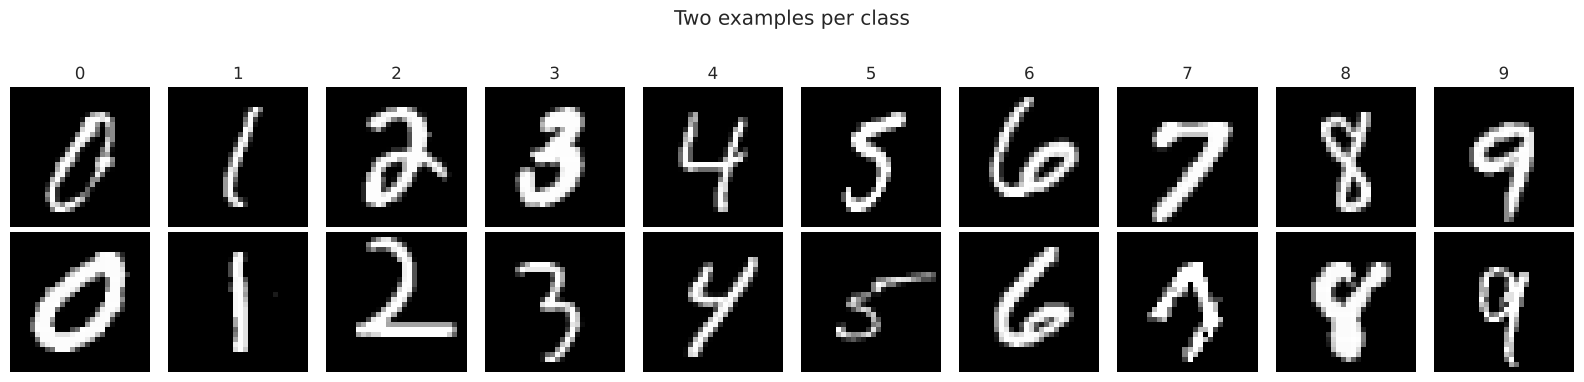

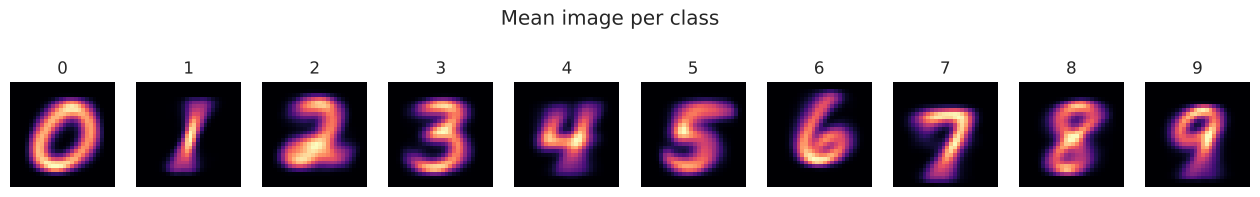

In [3]:
fig, axes = plt.subplots(2, 10, figsize=(16, 3.8))
for c in range(NUM_CLASSES):
    idx = np.where(labels == c)[0][:2]
    for r, i in enumerate(idx):
        axes[r, c].imshow(images[i], cmap="gray"); axes[r, c].axis("off")
        if r == 0: axes[r, c].set_title(CLASS_NAMES[c])
plt.suptitle("Two examples per class", y=1.02); plt.tight_layout(); plt.show()

# Average image per class shows how consistent / confusable the shapes are
fig, axes = plt.subplots(1, 10, figsize=(16, 2))
for c in range(NUM_CLASSES):
    axes[c].imshow(images[labels == c].mean(axis=0), cmap="magma"); axes[c].axis("off"); axes[c].set_title(CLASS_NAMES[c])
plt.suptitle("Mean image per class", y=1.12); plt.show()

## 2. Preprocessing and split

* Scale pixels to [0, 1] and add a channel dimension (28×28×1).
* Stratified split: **70 % train / 15 % validation / 15 % test**. The validation set drives early stopping; the test set is used exactly once at the end.

In [4]:
X = (images.astype("float32") / 255.0)[..., np.newaxis]
y = labels

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)
print(f"train {X_train.shape[0]} | validation {X_val.shape[0]} | test {X_test.shape[0]}")

train 7000 | validation 1500 | test 1500


## 3. Baseline: SVM on raw pixels

A strong classical baseline, so we can see what the CNN actually adds.

In [5]:
import time
t0 = time.time()
svm = SVC(kernel="rbf", C=5, gamma="scale")
svm.fit(X_train.reshape(len(X_train), -1), y_train)
svm_pred = svm.predict(X_test.reshape(len(X_test), -1))
svm_acc = accuracy_score(y_test, svm_pred)
print(f"SVM (RBF) test accuracy: {svm_acc:.4f}   (trained in {time.time() - t0:.0f}s)")

SVM (RBF) test accuracy: 0.9687   (trained in 5s)


## 4. CNN model

Architecture: three convolutional blocks (Conv → BatchNorm → ReLU → MaxPool; BatchNorm momentum is set to 0.9 because with a small dataset there are few training steps and the default 0.99 lets the running statistics lag behind, which wrecks validation accuracy) that learn strokes, then loops/corners, then whole-character parts, followed by dropout and a dense soft-max classifier. Light **data augmentation** (small rotations, shifts and zooms) is applied only during training, which imitates the natural variation between writers.

In [6]:
def build_cnn(num_classes=NUM_CLASSES):
    augment = keras.Sequential([
        layers.RandomRotation(0.08),
        layers.RandomTranslation(0.08, 0.08),
        layers.RandomZoom(0.10),
    ], name="augmentation")

    inputs = keras.Input(shape=(28, 28, 1))
    x = augment(inputs)
    for filters in (32, 64, 128):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization(momentum=0.9)(x)
        x = layers.Activation("relu")(x)
        if filters != 128:
            x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
            x = layers.BatchNormalization(momentum=0.9)(x)
            x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(0.25)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="handwriting_cnn")

model = build_cnn()
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "handwriting_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 157,610 (615.66 KB)

 Trainable params: 156,970 (613.16 KB)

 Non-trainable params: 640 (2.50 KB)

## 5. Training

Early stopping restores the best weights and `ReduceLROnPlateau` lowers the learning rate when the validation loss stalls.

In [7]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1),
]
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=EPOCHS if "EPOCHS" in globals() else 25,
                    batch_size=128, callbacks=callbacks, verbose=2)

Epoch 1/25


55/55 - 10s - 187ms/step - accuracy: 0.3271 - loss: 1.9199 - val_accuracy: 0.6307 - val_loss: 1.1805 - learning_rate: 0.0010


Epoch 2/25


55/55 - 7s - 133ms/step - accuracy: 0.6816 - loss: 0.9917 - val_accuracy: 0.8660 - val_loss: 0.4750 - learning_rate: 0.0010


Epoch 3/25


55/55 - 11s - 194ms/step - accuracy: 0.8394 - loss: 0.5395 - val_accuracy: 0.8467 - val_loss: 0.5015 - learning_rate: 0.0010


... (41 outputs left out)

Epoch 24/25


55/55 - 7s - 136ms/step - accuracy: 0.9767 - loss: 0.0752 - val_accuracy: 0.9900 - val_loss: 0.0312 - learning_rate: 5.0000e-04


Epoch 25/25


55/55 - 10s - 184ms/step - accuracy: 0.9771 - loss: 0.0785 - val_accuracy: 0.9907 - val_loss: 0.0269 - learning_rate: 5.0000e-04


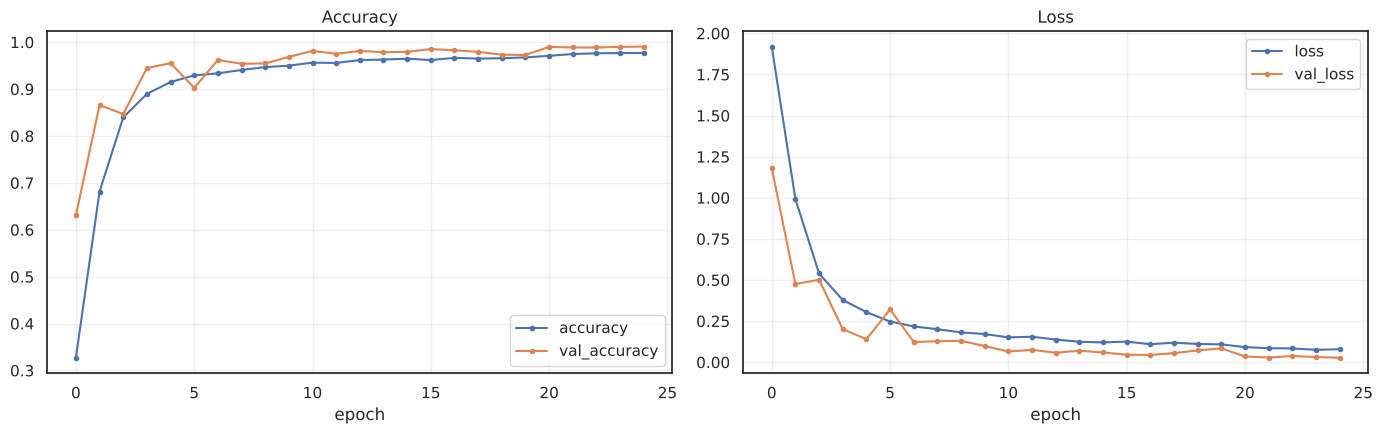

In [8]:
hist = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
hist[["accuracy", "val_accuracy"]].plot(ax=axes[0], marker="o", ms=3); axes[0].set_title("Accuracy"); axes[0].set_xlabel("epoch")
hist[["loss", "val_loss"]].plot(ax=axes[1], marker="o", ms=3); axes[1].set_title("Loss"); axes[1].set_xlabel("epoch")
for a in axes: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 6. Evaluation on the untouched test set

In [9]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
probs = model.predict(X_test, verbose=0)
pred = probs.argmax(axis=1)

print(f"CNN test accuracy: {test_acc:.4f}   |   SVM baseline: {svm_acc:.4f}")
print()
print(classification_report(y_test, pred, target_names=CLASS_NAMES, digits=3))

CNN test accuracy: 0.9907   |   SVM baseline: 0.9687

              precision    recall  f1-score   support

           0      0.993     1.000     0.997       150
           1      0.994     0.994     0.994       169
           2      0.980     1.000     0.990       149
           3      1.000     0.987     0.994       155
           4      0.993     1.000     0.997       147
           5      0.992     1.000     0.996       129
           6      1.000     0.993     0.997       152
           7      0.982     1.000     0.991       161
           8      0.986     0.979     0.982       141
           9      0.986     0.952     0.969       147

    accuracy                          0.991      1500
   macro avg      0.991     0.991     0.991      1500
weighted avg      0.991     0.991     0.991      1500



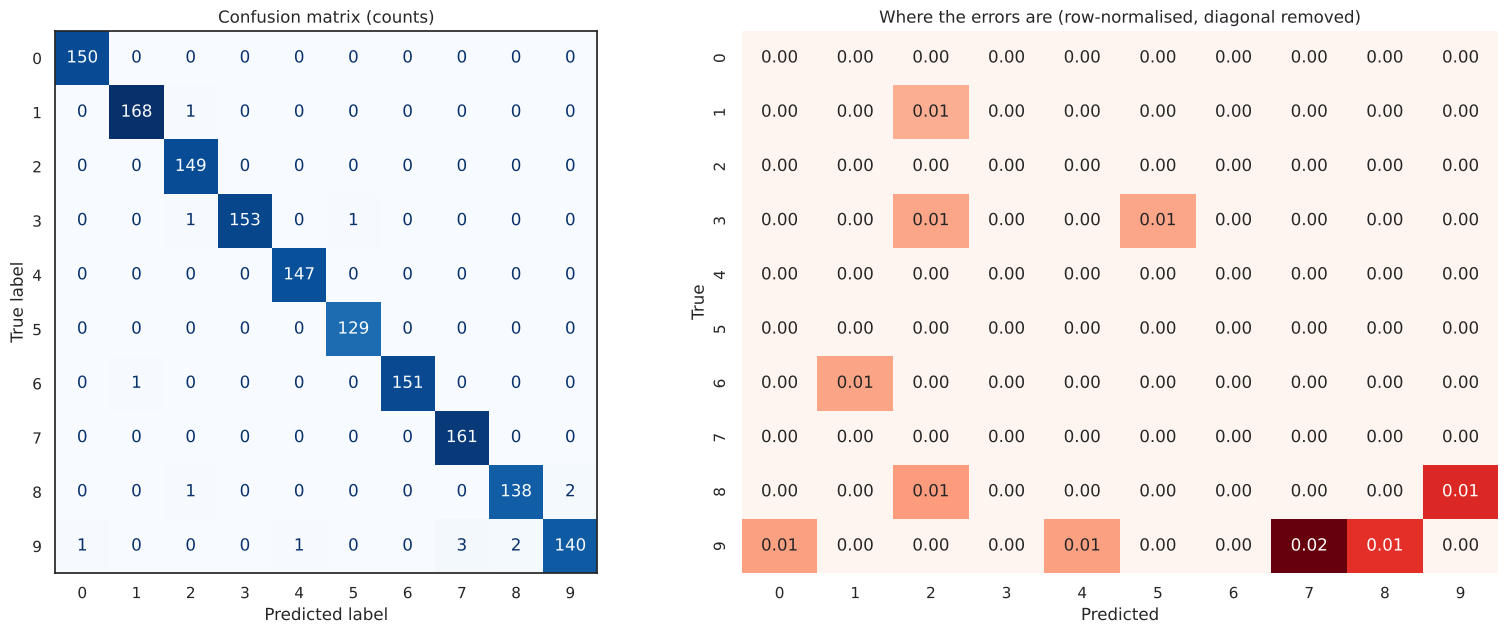

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=CLASS_NAMES, cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Confusion matrix (counts)")
cm = confusion_matrix(y_test, pred, normalize="true")
np.fill_diagonal(cm, 0)
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Reds", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False, ax=axes[1])
axes[1].set_title("Where the errors are (row-normalised, diagonal removed)")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("True")
plt.tight_layout(); plt.show()

## 7. Error analysis

Looking at the images the network gets wrong, together with its confidence, tells us whether the mistakes are reasonable (ambiguous handwriting) or a model problem.

14 misclassified out of 1500 test images


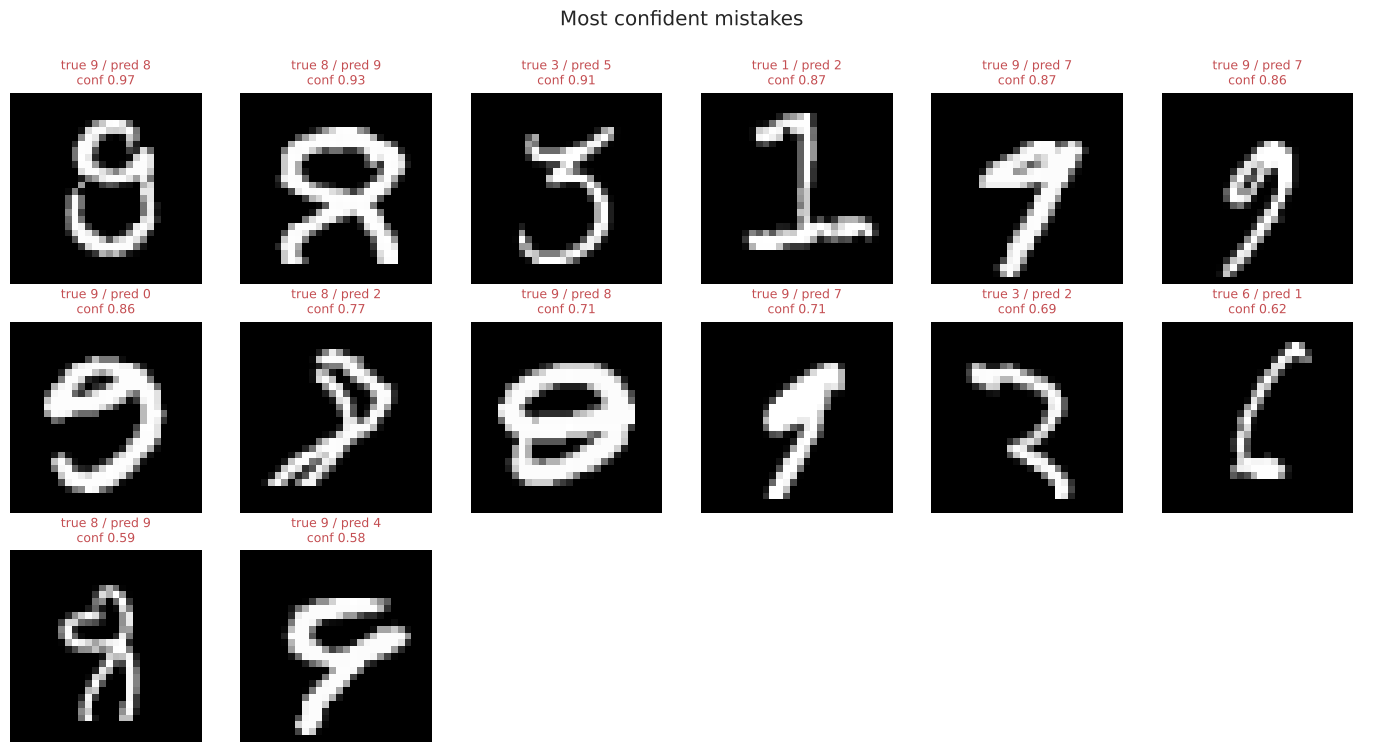

In [11]:
wrong = np.where(pred != y_test)[0]
print(f"{len(wrong)} misclassified out of {len(y_test)} test images")
order = wrong[np.argsort(-probs[wrong].max(axis=1))][:18]          # most confident mistakes first

fig, axes = plt.subplots(3, 6, figsize=(14, 7.5))
for ax, i in zip(axes.ravel(), order):
    ax.imshow(X_test[i, ..., 0], cmap="gray"); ax.axis("off")
    ax.set_title(f"true {CLASS_NAMES[y_test[i]]} / pred {CLASS_NAMES[pred[i]]}\nconf {probs[i].max():.2f}", fontsize=9, color="#C44E52")
for ax in axes.ravel()[len(order):]: ax.axis("off")
plt.suptitle("Most confident mistakes", y=1.0); plt.tight_layout(); plt.show()

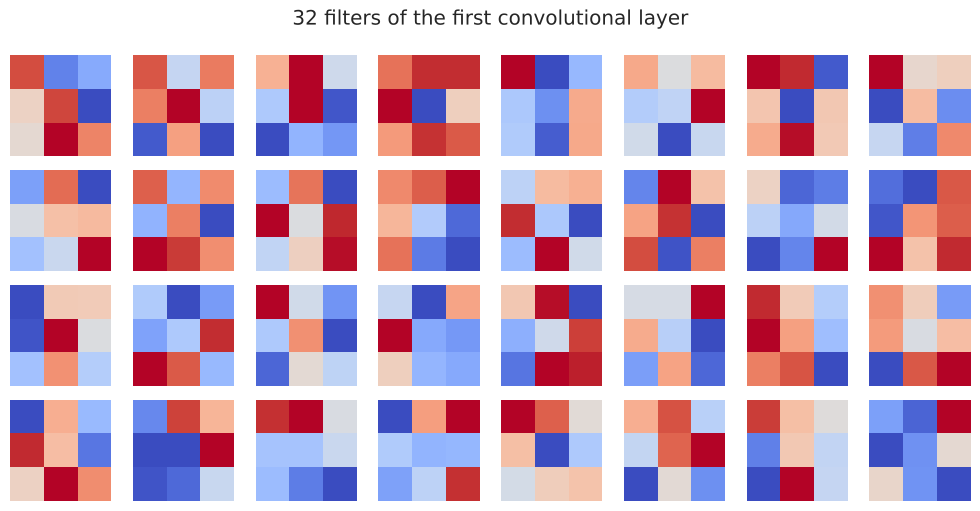

In [12]:
# What do the learned filters in the first convolution look like?
first_conv = [l for l in model.layers if isinstance(l, layers.Conv2D)][0]
w = first_conv.get_weights()[0]                                    # (3, 3, 1, 32)
fig, axes = plt.subplots(4, 8, figsize=(10, 5.2))
for k, ax in enumerate(axes.ravel()):
    ax.imshow(w[:, :, 0, k], cmap="coolwarm"); ax.axis("off")
plt.suptitle("32 filters of the first convolutional layer"); plt.tight_layout(); plt.show()

## 8. Recognise your own handwriting

`predict_image` accepts a path to any image (PNG/JPG). It converts to grayscale, **inverts to white-on-black if needed**, crops to the character, pads it to a square and resizes to 28×28 just like MNIST. Below we demo it on a synthetic test image rendered here; replace the path with a photo/scan of your own digit.

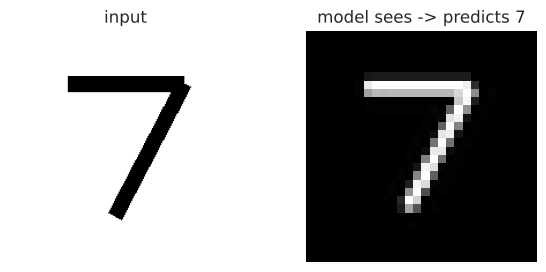

[('7', 0.9994), ('1', 0.0004), ('2', 0.0001)]


In [13]:
from PIL import Image, ImageDraw, ImageOps

def preprocess_image(img: Image.Image) -> np.ndarray:
    g = ImageOps.grayscale(img)
    a = np.asarray(g, dtype="float32")
    if a.mean() > 127:                      # dark ink on light paper -> invert to match MNIST (white on black)
        a = 255 - a
    ys, xs = np.where(a > 40)
    if len(xs) == 0:
        raise ValueError("No character found in the image")
    a = a[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    side = int(max(a.shape) * 1.25)
    canvas = np.zeros((side, side), dtype="float32")
    oy, ox = (side - a.shape[0]) // 2, (side - a.shape[1]) // 2
    canvas[oy:oy + a.shape[0], ox:ox + a.shape[1]] = a
    small = Image.fromarray(canvas.astype("uint8")).resize((20, 20), Image.LANCZOS)   # MNIST digits occupy a 20x20 box
    out = np.zeros((28, 28), dtype="float32"); out[4:24, 4:24] = np.asarray(small)
    return out / 255.0

def predict_image(path_or_image, show=True, top_k=3):
    img = Image.open(path_or_image) if isinstance(path_or_image, (str, os.PathLike)) else path_or_image
    x = preprocess_image(img)
    p = model.predict(x[np.newaxis, ..., np.newaxis], verbose=0)[0]
    best = np.argsort(-p)[:top_k]
    if show:
        fig, ax = plt.subplots(1, 2, figsize=(7, 3))
        ax[0].imshow(img, cmap="gray"); ax[0].set_title("input"); ax[0].axis("off")
        ax[1].imshow(x, cmap="gray"); ax[1].set_title(f"model sees -> predicts {CLASS_NAMES[best[0]]}"); ax[1].axis("off")
        plt.show()
    return [(CLASS_NAMES[i], round(float(p[i]), 4)) for i in best]

# demo with a computer-drawn "7" (black ink on white paper)
demo = Image.new("L", (200, 200), 255)
d = ImageDraw.Draw(demo)
d.line([(50, 45), (150, 45)], fill=0, width=14); d.line([(150, 45), (90, 160)], fill=0, width=14)
print(predict_image(demo))

In [14]:
# Save the trained network so it can be re-used without re-training
os.makedirs("outputs", exist_ok=True)
model.save("outputs/handwriting_cnn.keras")
print("Saved ->", os.path.abspath("outputs/handwriting_cnn.keras"))

Saved -> /home/claude/work/CodeAlpha_ML/CodeAlpha_HandwrittenCharacterRecognition/outputs/handwriting_cnn.keras


## 9. Conclusion

* The CNN clearly outperforms the pixel-based SVM baseline, and augmentation + dropout keep the gap between training and validation accuracy small.
* Only a small number of test images are misclassified (about 1 %); the confusion matrix and the "most confident mistakes" grid in sections 6-7 show which digit pairs are mixed up and that many of these images are genuinely ambiguous or sloppily written.
* The preprocessing function makes the model usable on real photos, not only on the dataset.

**Next steps:** train on the full 60k/70k MNIST or on EMNIST for letters, try a deeper ResNet-style network, add test-time augmentation and ensemble several CNNs.